<a href="https://colab.research.google.com/github/conniepadillav-prog/Machine-Learning-/blob/main/Semana_7_Photoz_RandomForests.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Random Forests and Photo-zs

En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [6]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14)
matplotlib.rc('ytick', labelsize=14)
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [7]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [8]:
#!pip install astropy
import astropy

from astropy.io import fits


#### Importamos los datos

Leemos el archivo fits y lo leemos usando pandas

In [11]:
with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
    arr = np.array(data[1].data).byteswap()
    df = pd.DataFrame(arr.view(arr.dtype.newbyteorder()))
    #https://numpy.org/doc/2.1/user/byteswapping.html

In [12]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [13]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,b'',b'',b'11001673',b'1101',b'000',b'2003-05-06',52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"b'bext, bcol, possible OII'",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,b'GALAXY',b'',b'11001699',b'1100',b'7',b'2003-05-03',52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,b'',-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,b'GALAXY',b'',b'11001770',b'1101',b'003',b'2003-05-06',52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,b'',-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,b'GALAXY',b'',b'11001800',b'1100',b'004',b'2003-05-03',52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,b'',-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,b'GALAXY',b'',b'11001860',b'1101',b'10',b'2003-05-06',52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,b'',-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [14]:
df.shape

(23822, 78)

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [15]:
features = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor', 'y_apercor']]

In [16]:
target = df['zhelio']

### Ahora empezaremos a implementar nuestro modelo de Random Forest

Figura 5 del paper

 ![Performance of photometric redshift reconstruction](https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/mnras/488/4/10.1093_mnras_stz1866/1/stz1866fig5.jpeg?Expires=1764255560&Signature=YsogBmQvQ0CkbNXBEimFc23Rt9Slq~Q5qJGdV1YfvS3w-Z3IEJvD7FrYcOoSm6U0xY-gU~5JqYe2A7wjaHjQ~GAPOIZP8Kod-zh~1sxPBUDM3aj4kio313nsCcC-zCJRDd1OEvPncis9N7puYcPeqj2R3rSNaGk4QJCOBtGhE5-NLbwFbQFalDhy7dELFeMm4uZQxaCwNeJF1NsQBETobU-LK13KulZ51tMrLF1HiDEjQetQBvccYAG6sC2fTWrNNtv9lSl9PEaac9qHSycwfyDc8GeHPFyh~DmL7KSQM3V1PEEkjG6-RYrwZaXYBorj5PkR9ZLJQzoNqRxn4Gl7rg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA)

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [17]:
model = RandomForestRegressor()

In [18]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$

In [19]:
%%time
scores = cross_validate(model, features, target, cv=KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

CPU times: user 1min 52s, sys: 446 ms, total: 1min 53s
Wall time: 1min 55s


In [20]:
scores

{'fit_time': array([21.77958965, 21.54613733, 22.27623415, 22.2876761 , 23.85638762]),
 'score_time': array([0.24659157, 0.19965792, 0.18640637, 0.18920803, 0.18351793]),
 'test_score': array([0.30374587, 0.31707611, 0.31662261, 0.29968186, 0.31039216]),
 'train_score': array([0.87390248, 0.87809029, 0.87777045, 0.87689488, 0.87530844])}

Calcule el promedio y la desviación estándar de las métricas obtenidas.

In [21]:
train_mean = np.mean(scores['train_score'])
train_std = np.std(scores['train_score'])
test_mean = np.mean(scores['test_score'])
test_std = np.std(scores['test_score'])

print(f"Train R^2 score: {train_mean:.4f} +/- {train_std:.4f}")
print(f"Test R^2 score: {test_mean:.4f} +/- {test_std:.4f}")

Train R^2 score: 0.8764 +/- 0.0016
Test R^2 score: 0.3095 +/- 0.0069


**Qué puede decir de este resultado? Hay bias alto o varianza alta?**

El resultado nos muestra que el modelo presenta una varianza alta porque se ajusta bien a los datos de entrenamiento pero no logra generalizar a los datos de entrenamiento.

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [22]:
ypred = cross_val_predict(model, features, target, cv=KFold(n_splits=5, shuffle=True, random_state=10))

(0.0, 3.0)

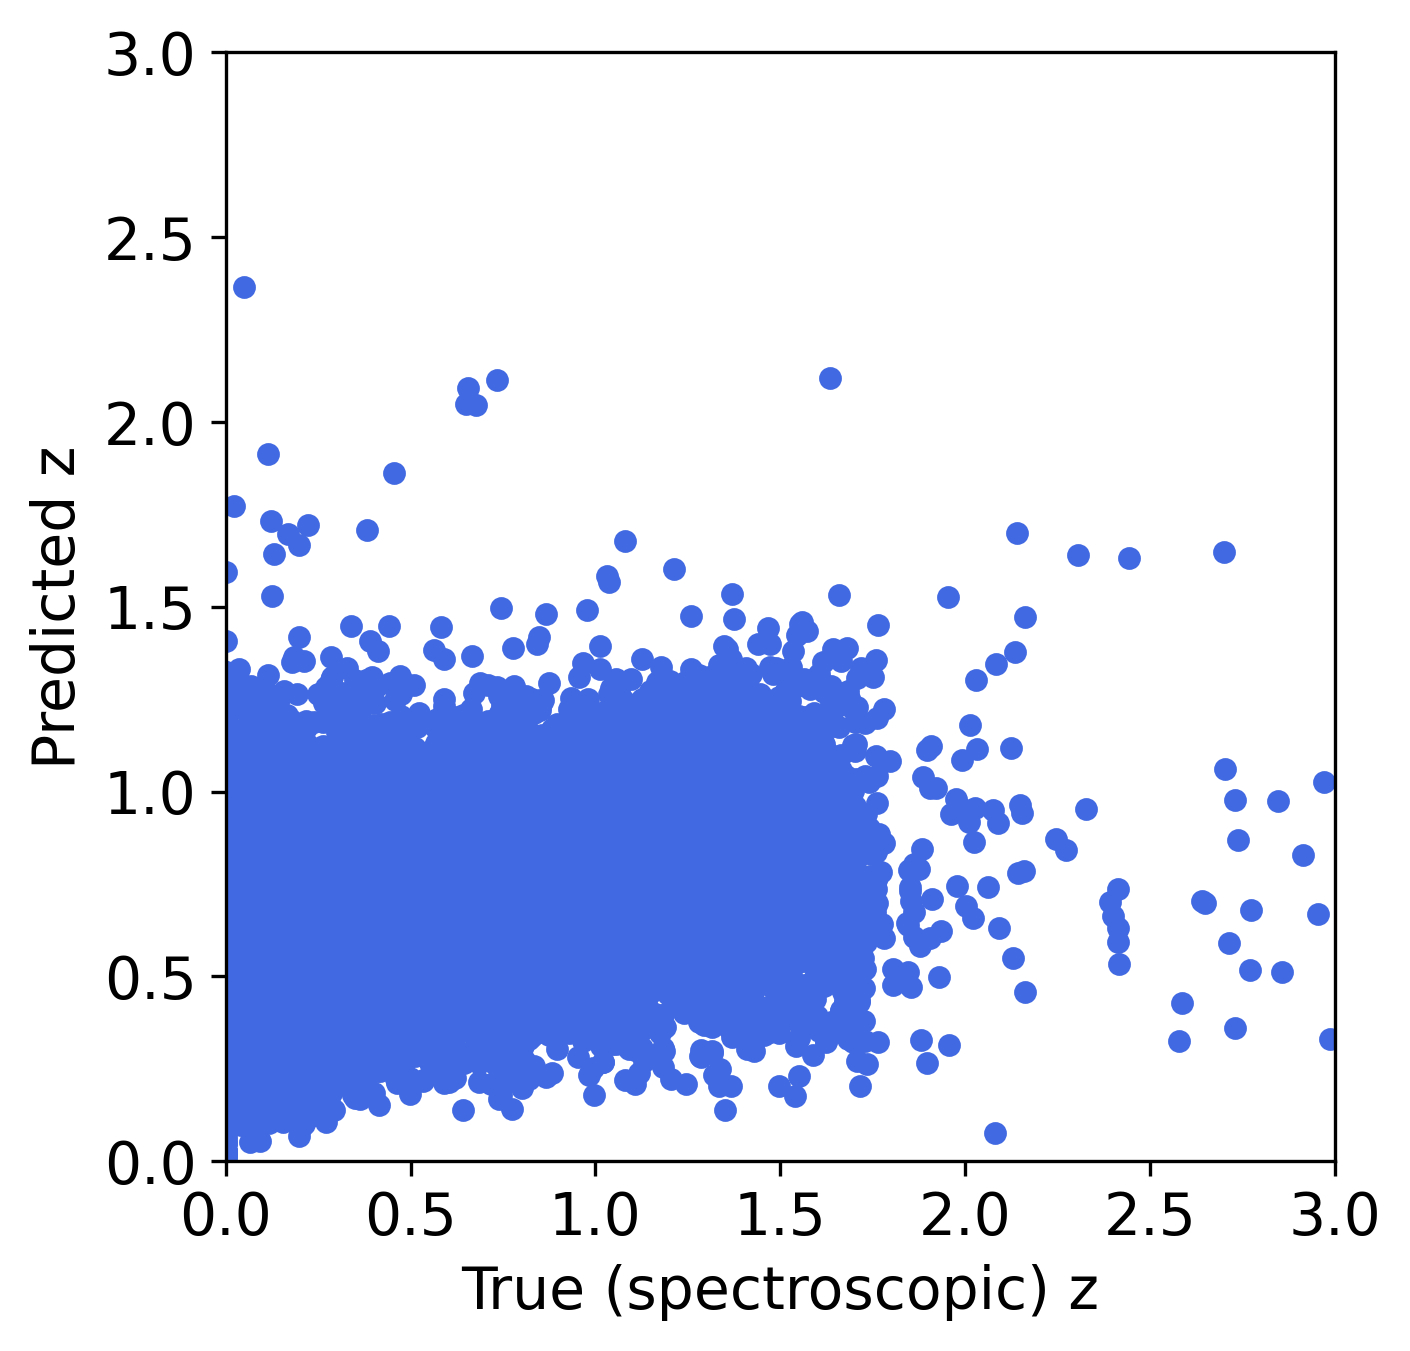

In [23]:
plt.scatter(target,ypred, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Se parece al resultado del paper??
Si se parecen

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha.

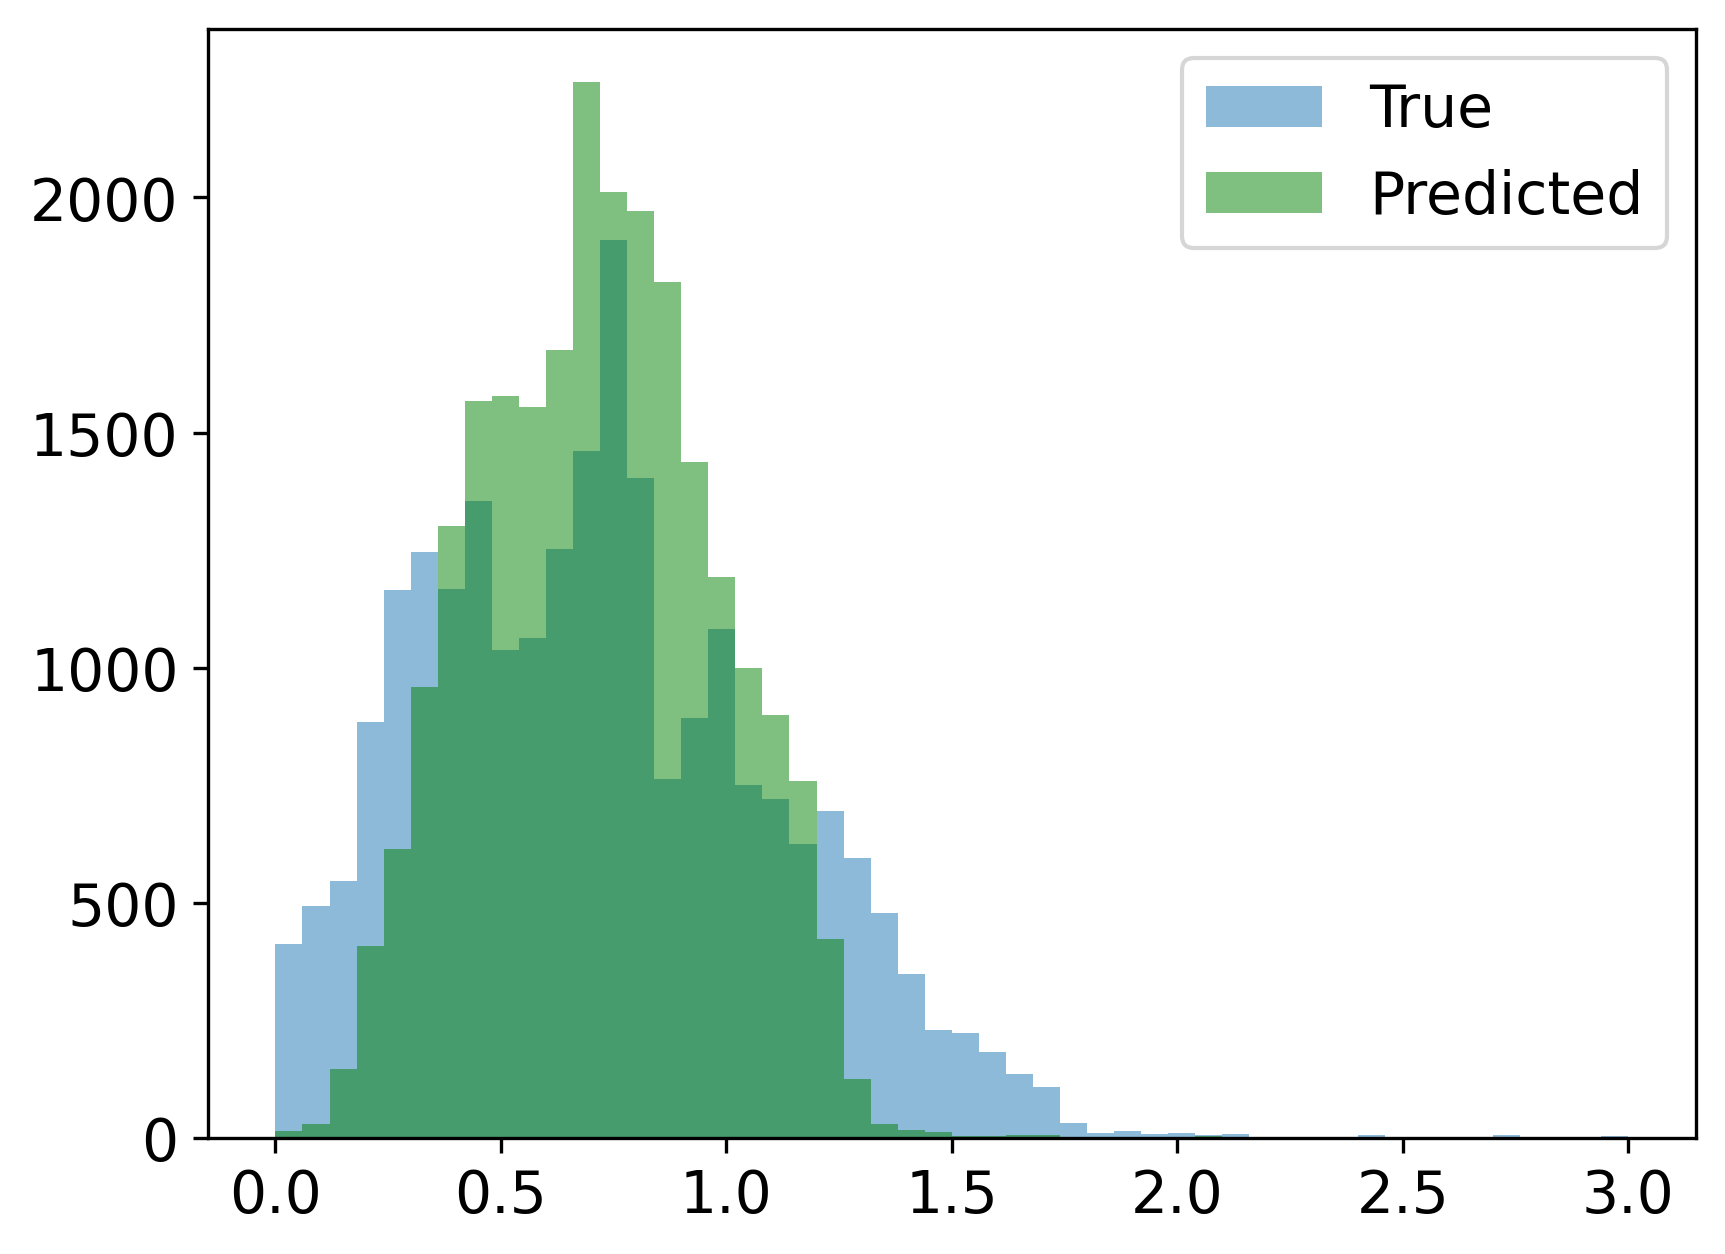

In [24]:
plt.hist(target,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);

Ahora calcule las métricas del paper, fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper

In [25]:
delta_z = ypred - target
relative_difference = np.abs(delta_z) / (1 + target)

# Calcular sigma_NMAD
mad = np.median(relative_difference)
sigma_nmad = 1.48 * mad

# Calcular fracción de outliers (eta)
outliers_mask = relative_difference > 0.15
eta = np.mean(outliers_mask)

print(f"sigma_NMAD: {sigma_nmad:.4f}")
print(f"Fracción de outliers (eta): {eta:.4f} ({eta * 100:.2f}%)")

sigma_NMAD: 0.0745
Fracción de outliers (eta): 0.2578 (25.78%)


y NMAD

In [26]:
mad = np.median(relative_difference)
print(f"NMAD: {mad:.4f}")

NMAD: 0.0503


Al calcular las métricas del modelo se obtuvo un valor de sigma NMAD=0.0745 y una fracción de outliers de eta=25.66.

Nuestro modelo presenta una mayor dispersión en las predicciones y un porcentaje de outliers considerablemente más alto. Para el campo Deep, el paper reporta un sigma NMAD=0.0174 y una fracción de outliers de 4.54 .

Estas diferencias pueden deberse a que todavía no hemos aplicado los mismos criterios de selección de datos utilizados en el paper. Además, los autores utilizan colores fotométricos como características de entrada para el Random Forest. Por lo tanto, nuestros resultados iniciales son menos precisos que los reportados en el artículo, pero podrían mejorar al seleccionar datos de mayor calidad y modificar las características utilizadas para entrenar el modelo.

### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [31]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), 5000, replace = False) #sample sin reemplazo

In [32]:
len(np.unique(sel))

5000

Y creamos nuestro nuevo dataset más pequeño

In [33]:
seld = features.loc[sel,:]
selt = target[sel]

Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [34]:
littlescores = cross_validate(model,seld,selt, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

In [35]:
littlescores['test_score'].mean(), littlescores['train_score'].mean()

(np.float64(0.27762715338769406), np.float64(0.8763722031531694))

### Estamos listos para optimizar hiperparámetros...cuáles escogemos?



#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [36]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper

- min_impurity_decrease

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [37]:
%%time
#Toma algunos minutos
parameters = {'min_impurity_decrease':[0.1, 0.5, 0.0], \
              'max_features':[None,4,2], 'n_estimators':[50, 100, 200], 'min_samples_split': [10,20,100],
              'max_leaf_nodes':[None, 100, 200]}
#... implemente el resto

CPU times: user 8 µs, sys: 0 ns, total: 8 µs
Wall time: 29.8 µs


In [53]:
from sklearn.model_selection import RandomizedSearchCV

# Solo 8 combinaciones x 3 particiones = 24 entrenamientos.
cv_opt = KFold(n_splits=3, shuffle=True, random_state=10)
busqueda = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=10, n_jobs=1),
    param_distributions=parameters,
    n_iter=8,
    cv=cv_opt,
    scoring='r2',
    random_state=10,
    return_train_score=True,
    n_jobs=2,
    verbose=1
)
busqueda.fit(seld, selt)
mejor_modelo = busqueda.best_estimator_
print('Mejores hiperparámetros:', busqueda.best_params_)
print(f'Mejor R² de validación cruzada: {busqueda.best_score_:.4f}')

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Mejores hiperparámetros: {'n_estimators': 50, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': None, 'max_features': 2}
Mejor R² de validación cruzada: 0.2969


Guardamos el resultado en un dataframe y buscamos el mejor modelo

In [54]:
scores_busqueda = pd.DataFrame(busqueda.cv_results_)
scoresCV = scores_busqueda[
    ['params', 'mean_test_score', 'std_test_score', 'mean_train_score']
].sort_values(by='mean_test_score', ascending=False)
scoresCV.head(8)


,params,mean_test_score,std_test_score,mean_train_score
2,"{'n_estimators': 50, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': No...",0.296944,0.006729,0.715269
0,"{'n_estimators': 100, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 1...",0.280533,0.007575,0.577892
5,"{'n_estimators': 100, 'min_samples_split': 100, 'min_impurity_decrease': 0.1, 'max_leaf_nodes': ...",-0.000173,0.000104,-0.000006
4,"{'n_estimators': 100, 'min_samples_split': 100, 'min_impurity_decrease': 0.5, 'max_leaf_nodes': ...",-0.000173,0.000104,-0.000006
6,"{'n_estimators': 200, 'min_samples_split': 20, 'min_impurity_decrease': 0.5, 'max_leaf_nodes': 2...",-0.000175,0.000117,-0.000002
3,"{'n_estimators': 200, 'min_samples_split': 100, 'min_impurity_decrease': 0.1, 'max_leaf_nodes': ...",-0.000175,0.000117,-0.000002
7,"{'n_estimators': 200, 'min_samples_split': 100, 'min_impurity_decrease': 0.1, 'max_leaf_nodes': ...",-0.000175,0.000117,-0.000002
1,"{'n_estimators': 50, 'min_samples_split': 10, 'min_impurity_decrease': 0.5, 'max_leaf_nodes': 20...",-0.000203,0.000116,-0.000005


In [55]:
benchmark_opt = cross_validate(
    RandomForestRegressor(n_estimators=100, random_state=10, n_jobs=1),
    seld, selt, cv=cv_opt, scoring='r2', n_jobs=2
)
r2_base = benchmark_opt['test_score'].mean()
r2_opt = busqueda.best_score_
print(f'R² base (3 folds):      {r2_base:.4f}')
print(f'R² optimizado (3 folds): {r2_opt:.4f}')
print(f'Diferencia:             {r2_opt-r2_base:+.4f}')
print('Nota: el mejor score de la búsqueda puede ser optimista por la selección de parámetros.')


R² base (3 folds):      0.2925
R² optimizado (3 folds): 0.2969
Diferencia:             +0.0044
Nota: el mejor score de la búsqueda puede ser optimista por la selección de parámetros.


In [56]:
scoresCV

,params,mean_test_score,std_test_score,mean_train_score
2,"{'n_estimators': 50, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': No...",0.296944,0.006729,0.715269
0,"{'n_estimators': 100, 'min_samples_split': 10, 'min_impurity_decrease': 0.0, 'max_leaf_nodes': 1...",0.280533,0.007575,0.577892
5,"{'n_estimators': 100, 'min_samples_split': 100, 'min_impurity_decrease': 0.1, 'max_leaf_nodes': ...",-0.000173,0.000104,-0.000006
4,"{'n_estimators': 100, 'min_samples_split': 100, 'min_impurity_decrease': 0.5, 'max_leaf_nodes': ...",-0.000173,0.000104,-0.000006
6,"{'n_estimators': 200, 'min_samples_split': 20, 'min_impurity_decrease': 0.5, 'max_leaf_nodes': 2...",-0.000175,0.000117,-0.000002
3,"{'n_estimators': 200, 'min_samples_split': 100, 'min_impurity_decrease': 0.1, 'max_leaf_nodes': ...",-0.000175,0.000117,-0.000002
7,"{'n_estimators': 200, 'min_samples_split': 100, 'min_impurity_decrease': 0.1, 'max_leaf_nodes': ...",-0.000175,0.000117,-0.000002
1,"{'n_estimators': 50, 'min_samples_split': 10, 'min_impurity_decrease': 0.5, 'max_leaf_nodes': 20...",-0.000203,0.000116,-0.000005


### Mejoran los scores?
Si mejoran los score, se obtuvo un valor máximo de R^2=0.2969en validación cruzada y R^2=0.7153 en entrenamiento. Sin embargo aun presenta sobreajuste.

### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [57]:
mags = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor','subaru_source','cfhtls_source','zquality']]



In [58]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [59]:
mags.shape

(23822, 9)

In [60]:
#zquality - solo usa objetos con medición de redshift de buena calidad

mags = mags[mags['zquality'] >= 3]

mags.shape

(16857, 9)

In [61]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data

mags = mags[mags['cfhtls_source'] == 0]

mags.shape

(10671, 9)

Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [62]:
mags = mags[mags > -10].dropna()

In [63]:
mags.shape

(6371, 9)

In [64]:
mags = mags[mags < 90].dropna()

In [65]:
mags.shape

(6307, 9)

Tenemos un dataset con las 6 features originales y 6307 objetos

In [66]:
sel_features = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [67]:
sel_target = target[sel_features.index]

**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.**

In [69]:
# Ejecutar el mismo benchmark .
cv_final = KFold(n_splits=5, shuffle=True, random_state=10)
modelo_final = RandomForestRegressor(n_estimators=100, random_state=10, n_jobs=1)
scores_new = cross_validate(
    modelo_final, sel_features, sel_target,
    cv=cv_final, return_train_score=True, scoring='r2', n_jobs=2
)
print(f'R² entrenamiento (filtrado): {scores_new["train_score"].mean():.4f}')
print(f'R² prueba (filtrado):       {scores_new["test_score"].mean():.4f}')


R² entrenamiento (filtrado): 0.9638
R² prueba (filtrado):       0.7457


In [70]:
# Predicciones sin entrenar en la misma galaxia que se evalua.
ypred_new = cross_val_predict(
    modelo_final, sel_features, sel_target, cv=cv_final, n_jobs=2
)

def metricas_photoz(y_real, y_pred):
    error = np.abs(np.asarray(y_pred) - np.asarray(y_real)) / (1 + np.asarray(y_real))
    sigma_nmad = 1.48 * np.median(error)
    eta_porcentaje = 100 * np.mean(error > 0.15)
    return sigma_nmad, eta_porcentaje

nmad_new, eta_new = metricas_photoz(sel_target, ypred_new)
print(f'Sigma NMAD filtrado: {nmad_new:.4f}')
print(f'Outliers filtrado:   {eta_new:.2f}%')


Sigma NMAD filtrado: 0.0358
Outliers filtrado:   5.42%


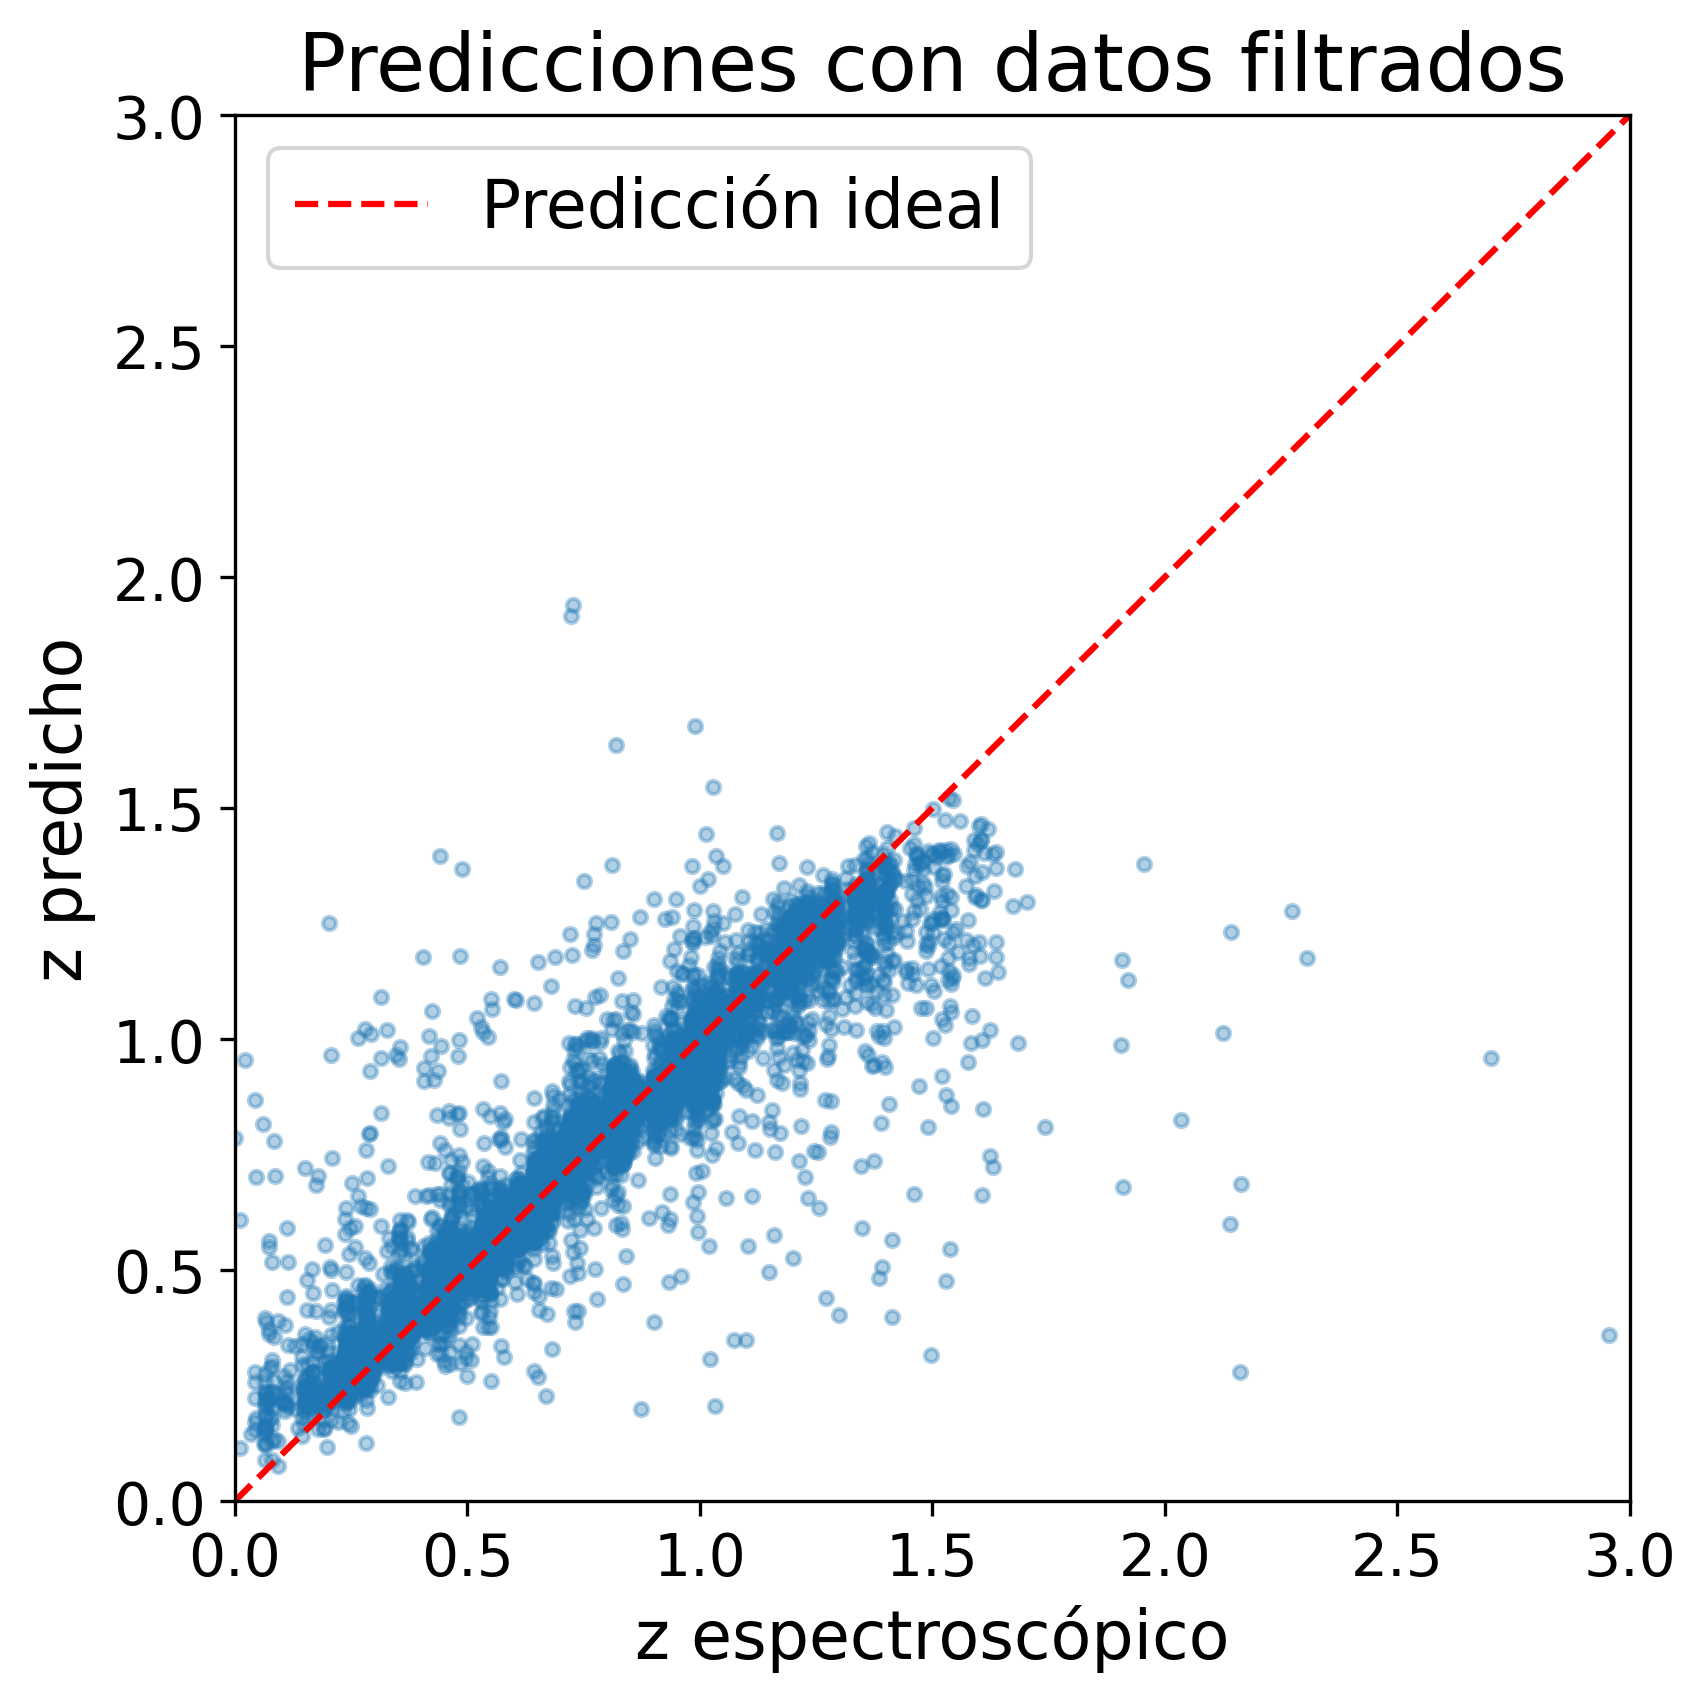

In [71]:
plt.figure(figsize=(6, 6))
plt.scatter(sel_target, ypred_new, s=10, alpha=0.35)
plt.plot([0,3], [0,3], 'r--', label='Predicción ideal')
plt.xlabel('z espectroscópico')
plt.ylabel('z predicho')
plt.title('Predicciones con datos filtrados')
plt.xlim(0, 3)
plt.ylim(0, 3)
plt.legend()
plt.show()


In [73]:
ypred_tuned = cross_val_predict(
    mejor_modelo, sel_features, sel_target, cv=cv_final, n_jobs=2
)
nmad_tuned, eta_tuned = metricas_photoz(sel_target, ypred_tuned)
comparacion_filtrado = pd.DataFrame({
    'Modelo': ['Benchmark filtrado', 'Hiperparámetros optimizados'],
    'R² (predicciones CV)': [metrics.r2_score(sel_target, ypred_new),
                            metrics.r2_score(sel_target, ypred_tuned)],
    'Sigma_NMAD': [nmad_new, nmad_tuned],
    'Outliers (%)': [eta_new, eta_tuned]
})
comparacion_filtrado.round(4)


,Modelo,R² (predicciones CV),Sigma_NMAD,Outliers (%)
0,Benchmark filtrado,0.7381,0.0358,5.4225
1,Hiperparámetros optimizados,0.7196,0.0458,7.1349


### Conclusion: Cómo se compara nuestro modelo con el resultado del paper?

Revise la sección 7 del paper. Podemos mejorar nuestro modelo aún más? Implemente un nuevo modelo con la mejora identificada



Si podemos mejorar nuestro modelo, intentando seguir la metodologia propuesta por el paper.
En lugar de utilizar directamente las seis magnitudes fotométricas, buscaremos calcular cinco colores mediante las diferencias entre magnitudes de filtros consecutivos, conservando también la magnitud del filtro i.
Para evaluar si existe una mejora, se compararan ambos modelos utilizando las mismas galaxias y particiones de validación cruzada, considerando las métricas R^2, sigmaNMAD y la fracción de outliers.

In [74]:
colores = pd.DataFrame(index=sel_features.index)
colores['u-g'] = sel_features['u_apercor'] - sel_features['g_apercor']
colores['g-r'] = sel_features['g_apercor'] - sel_features['r_apercor']
colores['r-i'] = sel_features['r_apercor'] - sel_features['i_apercor']
colores['i-z'] = sel_features['i_apercor'] - sel_features['z_apercor']
colores['z-y'] = sel_features['z_apercor'] - sel_features['y_apercor']
colores['i'] = sel_features['i_apercor']

ypred_colores = cross_val_predict(
    modelo_final, colores, sel_target, cv=cv_final, n_jobs=2
)
nmad_colores, eta_colores = metricas_photoz(sel_target, ypred_colores)

comparacion_final = pd.DataFrame({
    'Modelo': ['Seis magnitudes', 'Cinco colores + magnitud i'],
    'Sigma_NMAD': [nmad_new, nmad_colores],
    'Outliers (%)': [eta_new, eta_colores],
    'R²': [metrics.r2_score(sel_target, ypred_new),
           metrics.r2_score(sel_target, ypred_colores)]
})
print(comparacion_final.round(4).to_string(index=False))


                    Modelo  Sigma_NMAD  Outliers (%)     R²
           Seis magnitudes      0.0358        5.4225 0.7381
Cinco colores + magnitud i      0.0163        3.6785 0.8042


Al comparar los modelos podemos, podemos concluir que los cinco colores y la magnitud i mejoran considerablemente la predicción. El valor de sigmaNMAD disminuyó y el R^2 aumentó.
Esto puede explicarse porque los colores permiten representar de manera más directa las diferencias de brillo entre las bandas fotométricas, que están relacionadas con la forma del espectro y, por lo tanto, con el redshift de las galaxias.